#### AI in Production Management | Spring 2026 | Case Assignment
# Exercise 5: Three-Feature PLC Classification Rule

The SORTEX PLC can monitor only three original variables at a time. This notebook searches the final cleaned Exercise 3 master table for the best deployable three-feature rule under that old-hardware constraint.

The search uses only operationally admissible raw SORTEX columns, expands each triplet into PLC-allowed raw and division-ratio terms, fits shallow threshold trees, and selects the highest out-of-fold accuracy. Any batch that fails the rule is treated as **BAD**, matching the assignment's strict-quality framing.

Labels use the final project convention: `0 = BAD`, `1 = GOOD`.

In [1]:
from pathlib import Path
import re
import sys
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display
from sklearn.metrics import accuracy_score, average_precision_score, confusion_matrix, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.utils.validation import check_is_fitted
import xgboost as xgb

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="talk")
pd.set_option("display.max_columns", 140)
pd.set_option("display.max_rows", 180)

BASE_DIR = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
DATA_DIR_150825 = BASE_DIR / "data" / "DataDump_150825"
DATA_DIR_300825 = BASE_DIR / "data" / "DataDump_300825"
OUTPUT_DIR = BASE_DIR / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

BAD_CLASS = 0
GOOD_CLASS = 1
LABEL_NAMES = {BAD_CLASS: "BAD", GOOD_CLASS: "GOOD"}
RAW_TO_SEMANTIC_LABEL = {0: GOOD_CLASS, 1: BAD_CLASS}
BAD_SHIPPED_COST_CHF = 500
GOOD_WASTED_COST_CHF = 10

def feature_columns(df):
    return sorted([c for c in df.columns if c.startswith("feature_")], key=lambda c: int(c.split("_")[1]))

def standardize_manual_label(df, label_col="Manual_Label", raw_label_col="Manual_Label_Raw"):
    out = df.copy()
    raw = pd.to_numeric(out[label_col], errors="coerce")
    out[raw_label_col] = raw
    out[label_col] = raw.map(RAW_TO_SEMANTIC_LABEL).astype("Int64")
    return out

def add_label_name(df, label_col="Manual_Label"):
    out = df.copy()
    out[f"{label_col}_Name"] = out[label_col].map(LABEL_NAMES)
    return out

def load_master_table():
    df = pd.read_csv(OUTPUT_DIR / "exercise3_master_table_case_level.csv")
    if "Manual_Label" in df.columns:
        df["Manual_Label"] = pd.to_numeric(df["Manual_Label"], errors="coerce").astype("Int64")
    return df

def load_logbook_events():
    return pd.read_csv(OUTPUT_DIR / "logbook_events_structured.csv")

def load_heatwave_table():
    sensor = pd.read_csv(DATA_DIR_300825 / "sensor_data_august_shift.csv")
    quality = pd.read_csv(DATA_DIR_300825 / "quality_labels_august_shift.csv")
    production = pd.read_csv(DATA_DIR_300825 / "production_log_august_shift.csv", parse_dates=["Timestamp"])
    if len(sensor) != len(production):
        raise ValueError("Heatwave sensor and production logs should be row-aligned and equal length.")
    if not sensor["Charge_ID"].reset_index(drop=True).eq(production["Charge_ID"].reset_index(drop=True)).all():
        raise ValueError("Heatwave production rows are not row-aligned with sensor Charge_ID values.")
    table = sensor.merge(quality[["Case_ID", "Manual_Label", "Hash_Validation", "Legacy_Quality_Score"]], on="Case_ID", how="inner")
    if len(table) != len(sensor):
        raise ValueError("Heatwave quality merge changed row count; expected one label per Case_ID.")
    table = pd.concat([table.reset_index(drop=True), production.reset_index(drop=True)[["Timestamp", "Operator_ID"]]], axis=1)
    table = standardize_manual_label(table)
    table["label_available"] = table["Manual_Label"].notna()
    ts = pd.to_datetime(table["Timestamp"], errors="coerce")
    table["production_date"] = ts.dt.date
    table["production_hour"] = ts.dt.hour + ts.dt.minute / 60
    return add_label_name(table)

def _present_columns(df, cols):
    return [c for c in cols if c in df.columns]

def add_urs_rhythm_features(df, reference_df=None, source_features=("feature_2", "feature_4", "feature_5"), window=25):
    out = df.copy()
    signals = _present_columns(out, source_features)
    if not signals:
        raise ValueError("None of the rhythm source features are present.")
    reference = reference_df if reference_df is not None else out
    ref_numeric = reference[signals].apply(pd.to_numeric, errors="coerce")
    medians = ref_numeric.median()
    scales = ref_numeric.std().replace(0, np.nan).fillna(1.0)
    numeric = out[signals].apply(pd.to_numeric, errors="coerce").fillna(medians)
    standardized = (numeric - medians) / scales
    sort_cols = _present_columns(out, ["Timestamp_fixed", "Timestamp", "Charge_ID", "Case_ID"])
    ordered_index = out.sort_values(sort_cols).index if sort_cols else out.index
    ordered = standardized.loc[ordered_index]
    local_change = ordered.diff().abs().mean(axis=1).fillna(0.0)
    rolling_volatility = ordered.rolling(window=window, min_periods=3).std().mean(axis=1).fillna(0.0)
    rhythm = 0.4 * local_change + 0.6 * rolling_volatility
    out["Urs_Local_Signal_Change"] = local_change.reindex(out.index).astype(float)
    out["Urs_Rolling_Signal_Volatility"] = rolling_volatility.reindex(out.index).astype(float)
    out["Urs_Rhythm_Index"] = rhythm.reindex(out.index).astype(float)
    return out

def confusion_counts(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=[BAD_CLASS, GOOD_CLASS])
    return {
        "bad_correct": int(cm[0, 0]),
        "bad_shipped": int(cm[0, 1]),
        "good_wasted": int(cm[1, 0]),
        "good_correct": int(cm[1, 1]),
    }

def production_cost_chf(y_true, y_pred):
    counts = confusion_counts(y_true, y_pred)
    return counts["bad_shipped"] * BAD_SHIPPED_COST_CHF + counts["good_wasted"] * GOOD_WASTED_COST_CHF

def classification_summary(y_true, y_pred, model, threshold=None):
    counts = confusion_counts(y_true, y_pred)
    return {
        "model": model,
        "threshold": threshold,
        "rows": len(y_true),
        **counts,
        "bad_shipped_cost_chf": counts["bad_shipped"] * BAD_SHIPPED_COST_CHF,
        "good_wasted_cost_chf": counts["good_wasted"] * GOOD_WASTED_COST_CHF,
        "cost_chf": production_cost_chf(y_true, y_pred),
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_bad": precision_score(y_true, y_pred, pos_label=BAD_CLASS, zero_division=0),
        "recall_bad": recall_score(y_true, y_pred, pos_label=BAD_CLASS, zero_division=0),
        "precision_good": precision_score(y_true, y_pred, pos_label=GOOD_CLASS, zero_division=0),
        "recall_good": recall_score(y_true, y_pred, pos_label=GOOD_CLASS, zero_division=0),
    }

def confusion_frame(y_true, y_pred):
    return pd.DataFrame(
        confusion_matrix(y_true, y_pred, labels=[BAD_CLASS, GOOD_CLASS]),
        index=["Actual BAD (0)", "Actual GOOD (1)"],
        columns=["Pred BAD (0)", "Pred GOOD (1)"],
    )

def predict_from_bad_probability(prob_bad, threshold):
    return pd.Series(np.where(np.asarray(prob_bad) >= threshold, BAD_CLASS, GOOD_CLASS))

from itertools import combinations


## 1. Load the Exercise 3 Master Table and Define the Search Space

The search starts from the semantic Exercise 3 master table. Constant fields and exact duplicate copies are excluded because they cannot add deployable logic. `feature_31` is also excluded from the PLC search because the logbook identifies it as a destructive/offline Brix-style signal, which makes it unsuitable for real-time air-ejector control even though it is predictive in offline analysis.

In [2]:
OPERATOR_FAMILY = "raw_ratios"
EXCLUDED_FROM_PLC = {"feature_31": "logbook identifies Feature 31/Brix as destructive or unsuitable for live sorting"}

master = load_master_table()
data = master.dropna(subset=["Manual_Label"]).copy()
data["Manual_Label"] = data["Manual_Label"].astype(int)
features = feature_columns(data)
X = data[features].apply(pd.to_numeric, errors="coerce")
y = data["Manual_Label"]

nonconstant_features = [col for col in features if X[col].nunique(dropna=True) > 1]
unique_features = []
duplicate_feature_rows = []
for col in nonconstant_features:
    duplicate_of = None
    for kept in unique_features:
        if X[col].fillna(-999999999).equals(X[kept].fillna(-999999999)):
            duplicate_of = kept
            break
    if duplicate_of:
        duplicate_feature_rows.append({"excluded_feature": col, "reason": f"exact duplicate of {duplicate_of}"})
    else:
        unique_features.append(col)

candidate_features = [col for col in unique_features if col not in EXCLUDED_FROM_PLC]
exclusion_table = pd.DataFrame(
    duplicate_feature_rows + [{"excluded_feature": col, "reason": reason} for col, reason in EXCLUDED_FROM_PLC.items() if col in unique_features]
)

screening_rows = []
for col in unique_features:
    values = X[col]
    grouped = data.assign(_value=values).groupby("Manual_Label")["_value"].mean().to_dict()
    screening_rows.append({
        "feature": col,
        "mean_BAD_0": grouped.get(BAD_CLASS, np.nan),
        "mean_GOOD_1": grouped.get(GOOD_CLASS, np.nan),
        "abs_mean_gap": abs(grouped.get(BAD_CLASS, np.nan) - grouped.get(GOOD_CLASS, np.nan)),
        "corr_with_BAD": values.corr(y.eq(BAD_CLASS).astype(float)),
        "in_plc_search": col in candidate_features,
    })
screening = pd.DataFrame(screening_rows).sort_values("abs_mean_gap", ascending=False)

search_overview = pd.DataFrame([
    {"item": "labeled rows", "value": len(data)},
    {"item": "BAD rows (0)", "value": int((y == BAD_CLASS).sum())},
    {"item": "GOOD rows (1)", "value": int((y == GOOD_CLASS).sum())},
    {"item": "nonconstant unique raw features", "value": len(unique_features)},
    {"item": "operational PLC candidate features", "value": len(candidate_features)},
    {"item": "candidate triplets searched", "value": len(list(combinations(candidate_features, 3)))},
    {"item": "allowed arithmetic", "value": "raw variables and division ratios only"},
])

display(search_overview)
display(exclusion_table)
display(screening[["feature", "mean_BAD_0", "mean_GOOD_1", "abs_mean_gap", "corr_with_BAD", "in_plc_search"]].head(15))

,item,value
0,labeled rows,1404
1,BAD rows (0),722
2,GOOD rows (1),682
3,nonconstant unique raw features,15
4,operational PLC candidate features,14
5,candidate triplets searched,364
6,allowed arithmetic,raw variables and division ratios only


,excluded_feature,reason
0,feature_30,exact duplicate of feature_29
1,feature_31,logbook identifies Feature 31/Brix as destruct...


,feature,mean_BAD_0,mean_GOOD_1,abs_mean_gap,corr_with_BAD,in_plc_search
1,feature_2,300.527378,921.521318,620.993940,-0.580872,True
3,feature_4,60.554017,160.851906,100.297890,-0.620148,True
12,feature_31,74.534626,136.589443,62.054817,-0.710751,False
13,feature_32,14.903179,-43.606000,58.509179,0.628954,True
0,feature_1,20.478939,61.840198,41.361259,-0.633371,True
14,feature_33,5.500000,39.693548,34.193548,-0.620100,True
10,feature_27,1.152355,28.595308,27.442953,-0.278578,True
6,feature_9,12.333795,36.136364,23.802569,-0.511439,True
4,feature_5,14.853186,30.755132,15.901946,-0.548442,True
2,feature_3,15.941828,27.206745,11.264917,-0.555969,True


## 2. Search the Deployable Three-Feature Rule Space

Each candidate uses exactly three original PLC registers. The arithmetic transformer creates raw terms plus all ordered division ratios from those same three registers, which stays within the allowed operators. A shallow decision tree supplies the threshold logic and can be translated directly into IF/ELSE rules.

The ranking criterion is out-of-fold accuracy, because Exercise 5 asks for the highest-accuracy rule on the old hardware. CHF cost is still reported so Beat can see the operational trade-off.

In [3]:
class TripletSelector(BaseEstimator, TransformerMixin):
    def __init__(self, columns=None):
        self.columns = columns
    def fit(self, X, y=None):
        self.columns_ = list(self.columns)
        if len(self.columns_) != 3:
            raise ValueError("TripletSelector requires exactly three columns.")
        return self
    def transform(self, X):
        check_is_fitted(self, "columns_")
        return X.loc[:, self.columns_].copy()

class AllowedArithmeticTerms(BaseEstimator, TransformerMixin):
    def __init__(self, term_family="raw_ratios", eps=1e-12):
        self.term_family = term_family
        self.eps = eps
    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.n_features_in_ = X.shape[1]
        self.term_specs_ = [("raw", i) for i in range(self.n_features_in_)]
        if "ratios" in self.term_family:
            self.term_specs_.extend(("div", i, j) for i in range(self.n_features_in_) for j in range(self.n_features_in_) if i != j)
        return self
    def transform(self, X):
        check_is_fitted(self, "term_specs_")
        X = np.asarray(X, dtype=float)
        terms = []
        for spec in self.term_specs_:
            if spec[0] == "raw":
                terms.append(X[:, spec[1]])
            elif spec[0] == "div":
                numerator = X[:, spec[1]]
                denominator = X[:, spec[2]]
                ratio = np.full(X.shape[0], np.nan, dtype=float)
                np.divide(numerator, denominator, out=ratio, where=np.abs(denominator) > self.eps)
                terms.append(ratio)
        return np.column_stack(terms)
    def get_feature_names_out(self, input_features=None):
        input_features = list(input_features or [f"x{i}" for i in range(self.n_features_in_)])
        names = []
        for spec in self.term_specs_:
            if spec[0] == "raw":
                names.append(input_features[spec[1]])
            elif spec[0] == "div":
                names.append(f"({input_features[spec[1]]} / {input_features[spec[2]]})")
        return np.asarray(names, dtype=object)

def build_plc_pipeline(triplet, max_depth=3, min_samples_leaf=5, class_weight=None):
    return Pipeline([
        ("feature_selection", TripletSelector(columns=tuple(triplet))),
        ("raw_imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
        ("allowed_terms", AllowedArithmeticTerms(term_family=OPERATOR_FAMILY)),
        ("term_imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
        ("model", DecisionTreeClassifier(random_state=42, max_depth=max_depth, min_samples_leaf=min_samples_leaf, criterion="gini", class_weight=class_weight)),
    ])

def evaluate_candidate_predictions(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=[BAD_CLASS, GOOD_CLASS])
    bad_shipped = int(cm[0, 1])
    good_wasted = int(cm[1, 0])
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "bad_shipped": bad_shipped,
        "good_wasted": good_wasted,
        "cost_chf": bad_shipped * BAD_SHIPPED_COST_CHF + good_wasted * GOOD_WASTED_COST_CHF,
        "precision_bad": precision_score(y_true, y_pred, pos_label=BAD_CLASS, zero_division=0),
        "recall_bad": recall_score(y_true, y_pred, pos_label=BAD_CLASS, zero_division=0),
        "precision_good": precision_score(y_true, y_pred, pos_label=GOOD_CLASS, zero_division=0),
        "recall_good": recall_score(y_true, y_pred, pos_label=GOOD_CLASS, zero_division=0),
    }

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
search_param_grid = [
    {"max_depth": depth, "min_samples_leaf": leaf, "class_weight": None}
    for depth in [2, 3]
    for leaf in [5, 10]
]

search_rows = []
for triplet in combinations(candidate_features, 3):
    best_row = None
    for params in search_param_grid:
        pipeline = build_plc_pipeline(triplet, **params)
        candidate_pred = cross_val_predict(pipeline, X[list(triplet)], y, cv=cv, method="predict", n_jobs=None)
        row = evaluate_candidate_predictions(y, candidate_pred)
        row.update({"triplet": tuple(triplet), **params})
        if best_row is None or (row["accuracy"], -row["bad_shipped"], -row["good_wasted"]) > (best_row["accuracy"], -best_row["bad_shipped"], -best_row["good_wasted"]):
            best_row = row
    search_rows.append(best_row)

plc_search_results = pd.DataFrame(search_rows).sort_values(
    ["accuracy", "bad_shipped", "good_wasted", "cost_chf"],
    ascending=[False, True, True, True],
).reset_index(drop=True)
plc_search_results.insert(0, "rank", np.arange(1, len(plc_search_results) + 1))
plc_search_results.to_csv(OUTPUT_DIR / "exercise5_plc_search_results.csv", index=False)

best_record = plc_search_results.iloc[0].to_dict()
SELECTED_TRIPLET = tuple(best_record["triplet"])
SELECTED_PARAMS = {
    "max_depth": int(best_record["max_depth"]),
    "min_samples_leaf": int(best_record["min_samples_leaf"]),
    "class_weight": best_record["class_weight"] if pd.notna(best_record["class_weight"]) else None,
}
final_model = build_plc_pipeline(SELECTED_TRIPLET, **SELECTED_PARAMS).fit(X[list(SELECTED_TRIPLET)], y)

selected_rationale = pd.DataFrame([
    {"feature": feature, "role in final rule": "Selected by the constrained search as part of the highest-accuracy deployable triplet."}
    for feature in SELECTED_TRIPLET
])

display(plc_search_results.head(10)[["rank", "triplet", "accuracy", "bad_shipped", "good_wasted", "cost_chf", "precision_bad", "recall_bad", "precision_good", "recall_good", "max_depth", "min_samples_leaf"]])
display(selected_rationale)
display(Markdown(f"Selected PLC triplet: **{SELECTED_TRIPLET}** with out-of-fold accuracy **{best_record['accuracy']:.1%}** in the constrained search."))

,rank,triplet,accuracy,bad_shipped,good_wasted,cost_chf,precision_bad,recall_bad,precision_good,recall_good,max_depth,min_samples_leaf
0,1,"(feature_3, feature_10, feature_33)",0.908120,61,68,31180,0.906722,0.915512,0.909630,0.900293,3,5
1,2,"(feature_7, feature_10, feature_33)",0.906695,59,72,30220,0.902041,0.918283,0.911809,0.894428,3,5
2,3,"(feature_9, feature_10, feature_33)",0.906695,62,69,31690,0.905350,0.914127,0.908148,0.898827,3,10
3,4,"(feature_1, feature_10, feature_33)",0.905983,57,75,29250,0.898649,0.921053,0.914157,0.890029,3,10
4,5,"(feature_10, feature_11, feature_33)",0.905983,57,75,29250,0.898649,0.921053,0.914157,0.890029,3,5
5,6,"(feature_10, feature_12, feature_33)",0.905983,57,75,29250,0.898649,0.921053,0.914157,0.890029,3,5
6,7,"(feature_10, feature_27, feature_33)",0.905983,57,75,29250,0.898649,0.921053,0.914157,0.890029,3,5
7,8,"(feature_5, feature_10, feature_33)",0.905983,59,73,30230,0.900815,0.918283,0.911677,0.892962,3,5
8,9,"(feature_2, feature_10, feature_33)",0.905271,61,72,31220,0.901774,0.915512,0.909091,0.894428,3,10
9,10,"(feature_10, feature_32, feature_33)",0.905271,61,72,31220,0.901774,0.915512,0.909091,0.894428,3,5


,feature,role in final rule
0,feature_3,Selected by the constrained search as part of ...
1,feature_10,Selected by the constrained search as part of ...
2,feature_33,Selected by the constrained search as part of ...


Selected PLC triplet: **('feature_3', 'feature_10', 'feature_33')** with out-of-fold accuracy **90.8%** in the constrained search.

## 3. Validate the Selected PLC Rule

The table below re-evaluates the selected triplet with stratified out-of-fold predictions and exports the row-level predictions for Exercise 7. These are not training-set fitted labels; each prediction comes from a fold where that row was held out.

,model,rows,bad_shipped,good_wasted,cost_chf,accuracy,precision_bad,recall_bad,precision_good,recall_good
0,Exercise 5 three-feature PLC rule,1404,61,68,31180,0.90812,0.906722,0.915512,0.90963,0.900293


,Pred BAD (0),Pred GOOD (1)
Actual BAD (0),661,61
Actual GOOD (1),68,614


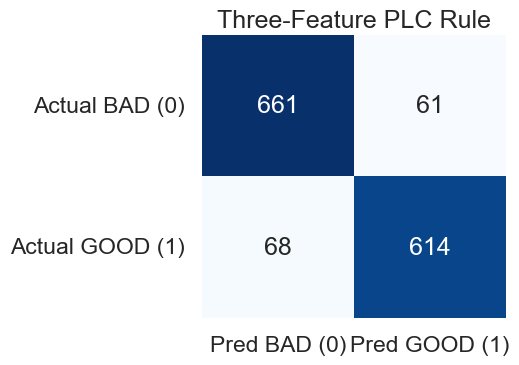

Saved Exercise 5 PLC predictions to `outputs/exercise5_plc_predictions.csv` for Exercise 7 comparison.

In [4]:
plc_model = build_plc_pipeline(SELECTED_TRIPLET, **SELECTED_PARAMS)
oof_pred = cross_val_predict(plc_model, X[list(SELECTED_TRIPLET)], y, cv=cv, method="predict", n_jobs=-1)
final_model = build_plc_pipeline(SELECTED_TRIPLET, **SELECTED_PARAMS).fit(X[list(SELECTED_TRIPLET)], y)

metrics = pd.DataFrame([classification_summary(y, oof_pred, "Exercise 5 three-feature PLC rule")])
cm = confusion_frame(y, oof_pred)

display(metrics[["model", "rows", "bad_shipped", "good_wasted", "cost_chf", "accuracy", "precision_bad", "recall_bad", "precision_good", "recall_good"]])
display(cm)

fig, ax = plt.subplots(figsize=(5.5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
ax.set_title("Three-Feature PLC Rule")
plt.tight_layout()
plt.show()

id_columns = [c for c in ["Case_ID", "Charge_ID"] if c in data.columns]
predictions = data.loc[y.index, id_columns].copy()
predictions.insert(0, "row_index", y.index)
predictions["actual_label"] = y.astype(int).to_numpy()
predictions["plc_pred_label"] = pd.Series(oof_pred, index=y.index).astype(int).to_numpy()
predictions["actual_quality"] = predictions["actual_label"].map(LABEL_NAMES)
predictions["plc_pred_quality"] = predictions["plc_pred_label"].map(LABEL_NAMES)
predictions["cv_strategy"] = "searched_three_feature_rule_stratified_oof"
predictions["selected_triplet"] = str(SELECTED_TRIPLET)
predictions["operator_family"] = OPERATOR_FAMILY
prediction_path = OUTPUT_DIR / "exercise5_plc_predictions.csv"
predictions.to_csv(prediction_path, index=False)
display(Markdown(f"Saved Exercise 5 PLC predictions to `{prediction_path.relative_to(BASE_DIR)}` for Exercise 7 comparison."))

## 4. PLC Rule Text

The final rule below is expressed as an IF/ELSE block. It can be implemented on the PLC because it uses only the three selected original features, ratio terms made from those features, threshold comparisons, and AND/OR logic.


In [5]:
def plc_identifier(text):
    text = str(text).replace("*", "_MUL_").replace("/", "_DIV_")
    text = text.replace("(", "").replace(")", "")
    text = re.sub(r"\W+", "_", text).strip("_")
    text = re.sub(r"_+", "_", text)
    return f"_{text}" if re.match(r"^\d", text) else text

def format_threshold(value, digits=10):
    text = f"{value:.{digits}g}"
    return text.rstrip("0").rstrip(".") if "." in text and "e" not in text.lower() else text

def term_names(fitted_pipeline):
    triplet = list(fitted_pipeline.named_steps["feature_selection"].columns_)
    return fitted_pipeline.named_steps["allowed_terms"].get_feature_names_out(triplet)

def extract_rules(fitted_pipeline):
    tree_model = fitted_pipeline.named_steps["model"]
    tree = tree_model.tree_
    classes = tree_model.classes_
    aliases = [plc_identifier(name) for name in term_names(fitted_pipeline)]
    rows = []
    def walk(node_id, conditions):
        left_id = tree.children_left[node_id]
        right_id = tree.children_right[node_id]
        if left_id == right_id:
            distribution = tree.value[node_id][0]
            predicted = classes[int(np.argmax(distribution))]
            rows.append({"condition": " AND ".join(conditions) if conditions else "TRUE", "prediction": LABEL_NAMES[int(predicted)], "support": int(tree.n_node_samples[node_id]), "purity": float(np.max(distribution) / np.sum(distribution)) if np.sum(distribution) else np.nan})
            return
        feature_alias = aliases[int(tree.feature[node_id])]
        threshold = format_threshold(tree.threshold[node_id])
        walk(left_id, conditions + [f"(({feature_alias} < {threshold}) OR ({feature_alias} == {threshold}))"])
        walk(right_id, conditions + [f"({feature_alias} > {threshold})"])
    walk(0, [])
    return pd.DataFrame(rows)

def rules_to_if_else(rule_df):
    lines = []
    for idx, row in rule_df.reset_index(drop=True).iterrows():
        if idx == len(rule_df) - 1:
            lines.extend(["ELSE", f"    {row['prediction']}"])
        else:
            lines.extend(["IF " + row["condition"] if idx == 0 else "ELSE IF " + row["condition"], f"THEN {row['prediction']}"])
    return "\n".join(lines)

rule_table = extract_rules(final_model)
used_terms = pd.DataFrame({"term": term_names(final_model), "plc_name": [plc_identifier(name) for name in term_names(final_model)], "importance": final_model.named_steps["model"].feature_importances_}).query("importance > 0").sort_values("importance", ascending=False)

display(used_terms)
display(rule_table)
print(rules_to_if_else(rule_table))


,term,plc_name,importance
7,(feature_33 / feature_3),feature_33_DIV_feature_3,0.934564
1,feature_10,feature_10,0.051214
2,feature_33,feature_33,0.009300
0,feature_3,feature_3,0.004923


,condition,prediction,support,purity
0,((feature_33_DIV_feature_3 < 0.4037037045) OR ...,BAD,8,0.875000
1,((feature_33_DIV_feature_3 < 0.4037037045) OR ...,BAD,17,0.647059
2,((feature_33_DIV_feature_3 < 0.4037037045) OR ...,BAD,678,0.915929
3,((feature_33_DIV_feature_3 < 0.4037037045) OR ...,BAD,11,0.636364
4,(feature_33_DIV_feature_3 > 0.4037037045) AND ...,GOOD,183,0.836066
5,(feature_33_DIV_feature_3 > 0.4037037045) AND ...,GOOD,492,0.936992
6,(feature_33_DIV_feature_3 > 0.4037037045) AND ...,BAD,15,1.000000


IF ((feature_33_DIV_feature_3 < 0.4037037045) OR (feature_33_DIV_feature_3 == 0.4037037045)) AND ((feature_3 < 10.5) OR (feature_3 == 10.5)) AND ((feature_3 < 8.5) OR (feature_3 == 8.5))
THEN BAD
ELSE IF ((feature_33_DIV_feature_3 < 0.4037037045) OR (feature_33_DIV_feature_3 == 0.4037037045)) AND ((feature_3 < 10.5) OR (feature_3 == 10.5)) AND (feature_3 > 8.5)
THEN BAD
ELSE IF ((feature_33_DIV_feature_3 < 0.4037037045) OR (feature_33_DIV_feature_3 == 0.4037037045)) AND (feature_3 > 10.5) AND ((feature_33 < 5.5) OR (feature_33 == 5.5))
THEN BAD
ELSE IF ((feature_33_DIV_feature_3 < 0.4037037045) OR (feature_33_DIV_feature_3 == 0.4037037045)) AND (feature_3 > 10.5) AND (feature_33 > 5.5)
THEN BAD
ELSE IF (feature_33_DIV_feature_3 > 0.4037037045) AND ((feature_10 < 8.5) OR (feature_10 == 8.5)) AND ((feature_33 < 27.5) OR (feature_33 == 27.5))
THEN GOOD
ELSE IF (feature_33_DIV_feature_3 > 0.4037037045) AND ((feature_10 < 8.5) OR (feature_10 == 8.5)) AND (feature_33 > 27.5)
THEN GOOD
ELSE
 

## 5. Final Exercise 5 Answer

- **Selected PLC features:** `feature_3`, `feature_10`, and `feature_33`.
- **How the rule was discovered:** the notebook searched all operationally admissible nonconstant, nonduplicate three-feature combinations from the final Exercise 3 master table, using only raw values and division ratios, and ranked them by stratified out-of-fold accuracy.
- **Allowed operations used:** comparisons, AND/OR logic, and division ratios built only from the three selected features.
- **Why this is superior to Urs' single intuition rule:** it combines three independent sensor registers, gives an auditable threshold rule, and validates performance on held-out folds instead of relying on intuition alone.
- **Business interpretation:** the rule is deployable on the old PLC and improves decision consistency, but it is still a constrained hardware compromise compared with the unrestricted Exercise 7 model.